In [1]:
import seaborn as sb
import numpy as np
import random
import math
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import functools as ft
import statistics
import scipy as sc
import pingouin as ping
import hyppo as hyp

In [ ]:
1. Продемонстрировать закон арксинуса для

(a) Первый вариант: момента пересечения нуля траекторией до момента n: построить на одном гра-
фике гистограмму последнего попадания в 0 и плотность из закона арксинуса при достаточно

большом n,
Второй вариант: момента первого достижения максимума на отрезке [0, n] при достаточно большом
n (по той же схеме),
(b) * доли времени, проведенной траекторией на положительной полуплоскости за промежуток [0, n]
(так же).

simple


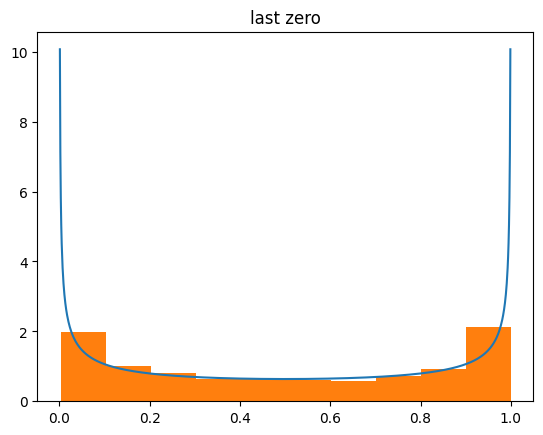

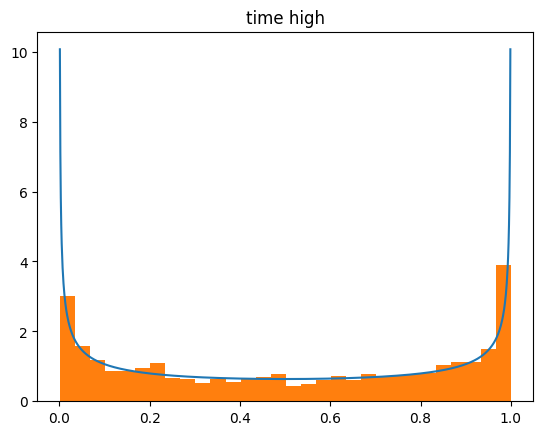

cauchy


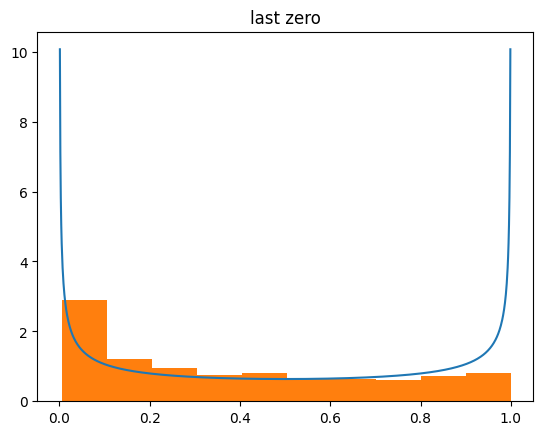

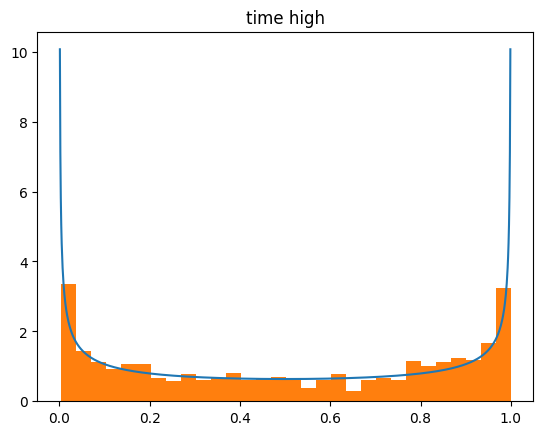

In [4]:
def gen_simple(n):
    s = [0]*(n)
    for k in range(1,n):
        s[k]=s[k-1] + 2*(np.random.binomial(1, 1/2) - 1/2)
    return s

def gen_cauchy(n):
    s = [0]*(n)
    for k in range(1,n):
        s[k]=s[k-1] + sc.stats.cauchy.rvs(loc = 0, size = 1)
    return s

def last_zero(s):
    n = len(s)
    for k in range(n):
        if (s[n-k-1]<=0 and s[n-k-2]>=0) or (s[n-k-1]>=0 and s[n-k-2]<=0):
            return n-k

def time_high(s):
    ans = 0
    for k in range(len(s)):
        if s[k]>=0:
            ans+=1
    return ans
    
n = 500 #длина блуждания
N = 2000 # количество блужданий

def main(n, N, random_walk, last_zero, time_high):
    last_zeroes = [0]*N
    high = [0]*N
    
    for k in range(N):
        s = random_walk(n)
        last_zeroes[k] = last_zero(s) / n
        high[k] = time_high(s) / n
        
    l = np.linspace(1/1000,1 - 1/1000,1000)
    
    plt.plot(l, 1/(np.pi * np.sqrt(l*(1-l)) ) )
    plt.hist(last_zeroes, density = "True")
    plt.title("last zero")
    plt.show()
    
    plt.plot(l, 1/(np.pi * np.sqrt(l*(1-l)) ) )
    plt.hist(high, density = "True", bins = 30)
    plt.title("time high")
    plt.show()

print("simple")
main(n, N, gen_simple, last_zero, time_high)


n = 300
N = 1000

print("cauchy")
main(n, N, gen_cauchy, last_zero, time_high)

In [ ]:
Убедиться, что СБ0 нулево возвратно. Для этого запустить траекторию, дождаться n таких возвраще-
ний и посчитать их среднюю длину. Как она ведет себя с ростом n?
Первый вариант: ПССБ

In [53]:
def main(n):
    ans = 0
    count = 0
    length = 0
    s = 0
    while count < n:
        s += 2*(np.random.binomial(1, 1/2) - 1/2)
        length+=1
        if s == 0:
            count+=1
            ans += length/n
            length = 0
    print(ans)

for n in [10, 100, 200, 300, 400]:
    print("n = ", n)
    for k in range(3):
        main(n)
    print("\n")

n =  10
14.399999999999995
1154.0
17.0


n =  100
67.64000000000009
83.87999999999987
189.34000000000017


n =  200
216.95999999999975
532.0799999999992
23136.559999999878


n =  300
251.56666666666558
9155.846666666645
5307.573333333384


n =  400
52558.3099999998
689.2499999999972
7550.8600000000415




In [ ]:
Проиллюстрировать закон повторного логарифма: построить на одном графике много траекторий слу-
чайного блуждания и графики функций y = ±

√
2n ln ln n. Рассмотреть ПССБ и СБ0 с распределением

шага N (0, 1).

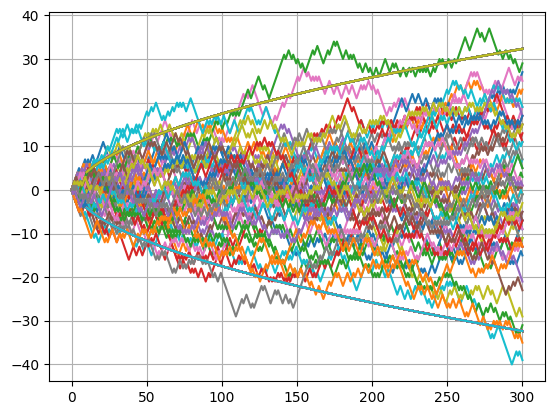

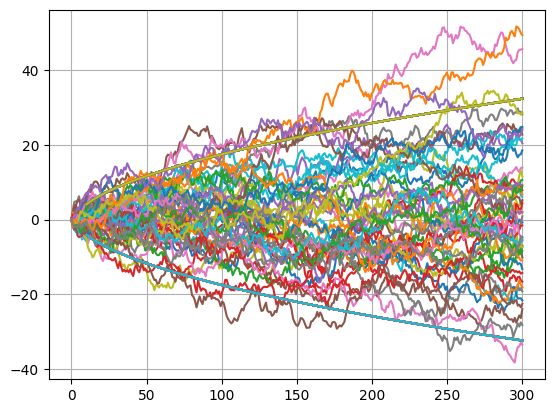

In [81]:
def gen_simple(n):
    s = [0]*(n)
    for k in range(1,n):
        s[k]=s[k-1] + 2*(np.random.binomial(1, 1/2) - 1/2)
    return s

def gen_norm(n):
    s = [0]*n
    for k in range(1,n):
        s[k]=s[k-1] + np.random.normal(0,1)
    return s

def graph(gen, n, N):
    l = np.linspace(0,n,n)
    l2 = np.linspace(10,n,n)
    for k in range(N):
        s = gen(n)
        plt.plot(l, s)
        plt.plot(l2, np.sqrt(2 * l2 * np.log(np.log(l2))))
        plt.plot(l2, -np.sqrt(2 * l2 * np.log(np.log(l2))))
        plt.grid(True)
    plt.show()

n = 300
N = 50
graph(gen_simple, n, N)

n = 300
N = 50
graph(gen_norm, n, N)

In [ ]:
Задача о разорении игрока. Пусть у игрока в начале есть A руб., каждую партию он выигрывает
с вероятностью p и получает за нее 1 руб. Игра прекращается, когда у игрока накапливается B руб.
или не остается денег. По n испытаниям найти эмпирические вероятности разорения для A = 10 и а)
B = 3A/2, б) B = 2A, в) B = 10A и сравнить их с теоретическими, также оценить среднее время
разорения (если вы их не считали, то можете взять ответы здесь.
(a) У первого варианта p = 1/2, у второго p = 1/3.

(b) * Пусть первый игрок выигрывает 2 рубля с вероятностью 1/3 и проигрывает 1 рубль с вероят-
ностью 2/3. Можно ли использовать ту же формулу для вероятности разорения? Почему с точки

зрения остановленных мартингалов тот же ответ уже не подходит?

In [11]:
def game(a, b):
    length = 0
    s = a
    while 1:
        length+=1
        s += 2*(np.random.binomial(1, 1/2, size = 1) - 1/2)
        if s==0:
            return length
        if s==b:
            return -1
        
def game2(a, b):
    length = 0
    s = a
    while 1:
        length+=1
        if(np.random.binomial(1, 1/3) == 1):
            s += 2
        else:
            s += -1
        if s==0:
            return length
        if s==b:
            return -1
n = 1000
a = 10
b = 10*a

for b in [3*a/2, 2*a, 10*a]:
    lose_time = [0]
    lose = 0
    a = 10
    for j in range (n):
        res = game(a, b)
        if res > 0 :
            lose+=1/n
            lose_time.append(res)
   
    print("A = ", a, "B = ", b, "P(lose) = ", 1-a/b, "E(lose time) = ", a*(b-a))
    print("P_hat(lose):", lose, "E_hat(lose time):", np.mean(lose_time))

"""
print("game2")

for b in [5*a]:
    lose_time = [0]*n
    lose = 0
    a = 10
    for j in range (n):
        res = game2(a, b)
        if res > 0 :
            lose+=1/n
            lose_time[j] = res
    lose_time = [x for x in lose_time if x!= 0]
    print("A = ", a, "B = ", b, "P(lose) = ", 1-a/b)
    print("P(lose):", lose)
"""

A =  10 B =  15.0 P(lose) =  0.33333333333333337 E(lose time) =  50.0
P_hat(lose): 0.33400000000000024 E_hat(lose time): 64.94925373134329
A =  10 B =  20 P(lose) =  0.5 E(lose time) =  100
P_hat(lose): 0.47400000000000037 E_hat(lose time): 97.91157894736843
A =  10 B =  100 P(lose) =  0.9 E(lose time) =  900
P_hat(lose): 0.9050000000000007 E_hat(lose time): 601.9845474613686


'\nprint("game2")\n\nfor b in [5*a]:\n    lose_time = [0]*n\n    lose = 0\n    a = 10\n    for j in range (n):\n        res = game2(a, b)\n        if res > 0 :\n            lose+=1/n\n            lose_time[j] = res\n    lose_time = [x for x in lose_time if x!= 0]\n    print("A = ", a, "B = ", b, "P(lose) = ", 1-a/b)\n    print("P(lose):", lose)\n'

In [21]:
def game(a, b):
    length = 0
    s = a
    while 1:
        length+=1
        s += 2*(np.random.binomial(1, 1/2, size = 1) - 1/2)
        if s==0:
            return [length, 0]
        if s==b:
            return [length, 1]

        
def game2(a, b):
    length = 0
    s = a
    while 1:
        length+=1
        if(np.random.binomial(1, 1/3) == 1):
            s += 2
        else:
            s += -1
        if s==0:
            return [length, 0]
        if s==b:
            return [length, 1]
n = 1000
a = 10
for b in [3*a/2, 2*a, 10*a]:
    lose_time = [0]
    lose = 0
    for j in range (n):
        res = game(a, b)
        if res[1] == 0 :
            lose+=1/n
        lose_time.append(res[0])
   
    print("A = ", a, "B = ", b, "P(lose) = ", 1-a/b, "E(lose time) = ", a*(b-a))
    print("P_hat(lose):", lose, "E_hat(lose time):", np.mean(lose_time))


print("game2","\n")
lose_time = [0]
lose = 0
b = 20*a/2
for j in range (n):
    res = game(a, b)
    if res[1] == 0 :
            lose+=1/n
print("A = ", a, "B = ", b, "P(lose) = ", 1-a/b)
print("P_hat(lose):", lose)

A =  10 B =  15.0 P(lose) =  0.33333333333333337 E(lose time) =  50.0
P_hat(lose): 0.32600000000000023 E_hat(lose time): 49.67432567432567
A =  10 B =  20 P(lose) =  0.5 E(lose time) =  100
P_hat(lose): 0.4920000000000004 E_hat(lose time): 99.77022977022978
A =  10 B =  100 P(lose) =  0.9 E(lose time) =  900
P_hat(lose): 0.9050000000000007 E_hat(lose time): 925.5944055944055
game2 

A =  10 B =  100.0 P(lose) =  0.9
P_hat(lose): 0.9010000000000007
